# A geological transferability index for cross-well uncertainty in shear-wave slowness prediction

Reproducible code for the analyses in the manuscript. Section numbers follow the manuscript.

**Inputs.** The well logs are confidential and are not distributed. Place two CSV files in the working directory:

| File | Content |
|---|---|
| `Well-1.csv` | Quality-controlled logs of Well-1 (Kailashtila) |
| `Well-2.csv` | Quality-controlled logs of Well-2 (Srikail) |

Both files need the columns `MD` (m), `BIT` (in), `CAL` (in), `GR` (API), `DT` (µs/ft), `DTS` (µs/ft), `NPHI` (v/v), `RHOB` (g/cm³) and `RES_DEEP` (ohm·m).

**Run time.** Set `FAST = True` for a quick check with reduced sample sizes. Numbers differ slightly from the manuscript in this mode. The full run takes about one hour on a CPU.

## 0. Setup

In [ ]:
%pip install -q shap xgboost statsmodels

In [2]:
import os, copy, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from scipy.spatial.distance import cdist
import statsmodels.api as sm
import xgboost as xgb, shap, tensorflow as tf
from IPython.display import display
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingClassifier
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, GroupKFold
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error, roc_auc_score

SEED = 42
FAST = False
N_BOOT = 200 if FAST else 3000       # bootstrap resamples
N_SHAP = 300 if FAST else 2000       # depth-spaced rows explained per well
ANN_EPOCHS = 40 if FAST else 300
N_MLP = 1 if FAST else 3             # networks averaged in the surrogate refits
BLOCK_M = 100                        # default depth-block length (m)
CLASS_HI, CLASS_LO = 0.8, 0.5        # provisional GTI class limits
ANN_VALIDATION = "test"              # "test": early stopping monitors the held-out 20 % split (as in the manuscript); "train": 10 % of the training rows
FEATS = ["DT", "NPHI", "RHOB", "GR", "RES_DEEP"]

np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
rng = np.random.default_rng(SEED)
pd.options.display.float_format = "{:.3f}".format
pd.options.display.width = 200
plt.rcParams.update({"font.size": 8, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})

I0000 00:00:1792882919.249539    5881 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1792882920.718607    5881 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [3]:
def ols(x, y):
    n = len(x); sx, sy = x.sum(), y.sum()
    b = (n * (x * y).sum() - sx * sy) / (n * (x * x).sum() - sx ** 2)
    return b, (sy - b * sx) / n

def maha(X, mu, S):
    d = X - mu
    return np.sqrt(np.einsum("ij,jk,ik->i", d, np.linalg.inv(S), d))

def in_env(ref, tgt):
    # True for target rows inside the 95 % Mahalanobis envelope of the reference logs
    A = ref[FEATS].values; mu, S = A.mean(0), np.cov(A.T)
    return maha(tgt[FEATS].values, mu, S) <= np.percentile(maha(A, mu, S), 95)

def slope_ratio(s1, s2):
    # min/max of two slopes; 0 if a resampled slope is not positive
    return max(0.0, min(s1, s2) / max(s1, s2)) if max(s1, s2) > 0 else 0.0

def gti_forms(D, R, I):
    return {"geometric": (D * R * I) ** (1 / 3), "weakest_link": min(D, R, I), "arithmetic": (D + R + I) / 3}

class Binned:
    # 10 m bins of sufficient statistics, so a depth block is a prefix-sum difference
    def __init__(s, d, flag=None, step=10.0):
        s.step = step; g = ((d.MD.values - d.MD.min()) // step).astype(int); s.nb = g.max() + 1
        x, y = d.DT.values, d.DTS.values
        cols = [np.ones(len(d)), x, y, x * x, x * y] + ([flag.astype(float)] if flag is not None else [])
        S = np.stack([np.bincount(g, weights=c, minlength=s.nb) for c in cols], 1)
        s.C = np.vstack([np.zeros(S.shape[1]), np.cumsum(S, 0)])
    def boot(s, L, rng):
        lb = max(1, int(round(L / s.step))); nblk = int(np.ceil(s.nb / lb))
        st = rng.integers(0, max(1, s.nb - lb + 1), nblk); e = np.minimum(st + lb, s.nb)
        return (s.C[e] - s.C[st]).sum(0)
    @staticmethod
    def slope(T):
        n, sx, sy, sxx, sxy = T[:5]
        return (n * sxy - sx * sy) / (n * sxx - sx ** 2)

## 1. Study wells and data quality control (Tables 1 and 2)

Physical bounds are applied to both wells. The depth-matched Well-1 subset starts at the shallowest Well-2 depth.

In [4]:
BOUNDS = {"GR": (0, 300), "DT": (40, 240), "DTS": (60, 400), "RHOB": (1.65, 2.95), "NPHI": (-0.05, 0.60),
          "RES_DEEP": (0.01, 2000), "CAL": (4, 20), "BIT": (4, 20)}

def load(path):
    d = pd.read_csv(path)
    for c, (lo, hi) in BOUNDS.items():
        d = d[d[c].between(lo, hi)]
    return d.dropna(subset=FEATS + ["DTS", "MD"]).sort_values("MD").reset_index(drop=True)

w1, w2 = load("Well-1.csv"), load("Well-2.csv")
DEEP_TOP = w2.MD.min()
w1d = w1[w1.MD >= DEEP_TOP].reset_index(drop=True)
sb, ib = ols(w2.DT.values, w2.DTS.values)
s_g, i_g = ols(w1.DT.values, w1.DTS.values)
s_d, i_d = ols(w1d.DT.values, w1d.DTS.values)

summary = pd.DataFrame({n: {"rows": len(d), "MD min (m)": d.MD.min(), "MD max (m)": d.MD.max(),
                            "DT mean": d.DT.mean(), "DTS mean": d.DTS.mean(), "DT-DTS slope": ols(d.DT.values, d.DTS.values)[0]}
                        for n, d in [("Well-1", w1), ("Well-1 depth-matched", w1d), ("Well-2", w2)]}).T
display(summary)

,rows,MD min (m),MD max (m),DT mean,DTS mean,DT-DTS slope
Well-1,27033.000,217.850,3466.750,102.273,166.869,0.616
Well-1 depth-matched,10424.000,2088.450,3466.750,83.839,150.288,1.541
Well-2,18019.000,2088.396,3499.944,80.331,145.117,1.846


## 4.1 Distribution shift (Tables 3 and 4)

In [5]:
def psi(ref, tgt, bins=10, eps=1e-4):
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1))); edges[0], edges[-1] = -np.inf, np.inf
    r = np.clip(np.histogram(ref, edges)[0] / len(ref), eps, None); t = np.clip(np.histogram(tgt, edges)[0] / len(tgt), eps, None)
    return float(((t - r) * np.log(t / r)).sum())

t3 = pd.DataFrame({c: {"KS": stats.ks_2samp(w1[c], w2[c])[0], "p": stats.ks_2samp(w1[c], w2[c])[1], "PSI": psi(w1[c], w2[c])}
                   for c in FEATS + ["DTS"]}).T
display(t3)

,KS,p,PSI
DT,0.527,0.000,3.904
NPHI,0.661,0.000,4.310
RHOB,0.447,0.000,1.257
GR,0.239,0.000,0.388
RES_DEEP,0.485,0.000,2.327
DTS,0.446,0.000,2.082


In [6]:
def block_id(d, L, offset=0):
    return ((d.MD.values - d.MD.min()) // L).astype(int) + offset

def shift_metrics(dA, dB):
    A, B = dA[FEATS].values, dB[FEATS].values
    mA, SA = A.mean(0), np.cov(A.T); mB, SB = B.mean(0), np.cov(B.T)
    cov_t = (maha(B, mA, SA) <= np.percentile(maha(A, mA, SA), 95)).mean()
    cov_s = (maha(A, mB, SB) <= np.percentile(maha(B, mB, SB), 95)).mean()
    X = np.vstack([A, B]); y = np.r_[np.zeros(len(A)), np.ones(len(B))]
    g = np.r_[block_id(dA, 100), block_id(dB, 100, 100000)]; p = np.zeros(len(y))
    for tr_i, te_i in GroupKFold(5).split(X, y, g):
        p[te_i] = HistGradientBoostingClassifier(max_iter=150, random_state=0).fit(X[tr_i], y[tr_i]).predict_proba(X[te_i])[:, 1]
    mu, sd = w1[FEATS].mean().values, w1[FEATS].std().values
    Xs = ((A - mu) / sd)[rng.choice(len(A), 2000, replace=False)]; Ys = ((B - mu) / sd)[rng.choice(len(B), 2000, replace=False)]
    ed = 2 * cdist(Xs, Ys).mean() - cdist(Xs, Xs).mean() - cdist(Ys, Ys).mean()
    return {"Well-2 inside Well-1 envelope": cov_t, "Well-1 inside Well-2 envelope": cov_s,
            "adversarial AUC (block CV)": roc_auc_score(y, p), "energy distance": ed,
            **{"Wasserstein " + c: stats.wasserstein_distance(dA[c], dB[c]) for c in FEATS + ["DTS"]}}

t4 = pd.DataFrame({"pooled": shift_metrics(w1, w2), "depth-matched": shift_metrics(w1d, w2)})
display(t4)

,pooled,depth-matched
Well-2 inside Well-1 envelope,0.781,0.850
Well-1 inside Well-2 envelope,0.320,0.742
adversarial AUC (block CV),0.980,0.933
energy distance,1.506,0.378
Wasserstein DT,21.960,4.150
Wasserstein NPHI,0.137,0.040
Wasserstein RHOB,0.144,0.071
Wasserstein GR,6.916,9.294
Wasserstein RES_DEEP,21.258,3.083
Wasserstein DTS,21.772,5.287


## 4.3 Relationship stability and inference with depth-block clusters (Table 7)

Residual autocorrelation sets the block length. The slope difference is tested with a Well-2 indicator interaction and cluster-robust errors, and the slope ratio is bootstrapped by depth block.

In [7]:
def acf_range(d, nlag):
    s, i = ols(d.DT.values, d.DTS.values); r = d.DTS.values - (i + s * d.DT.values); r = r - r.mean()
    a = np.array([(r[:len(r) - l] * r[l:]).sum() / (r * r).sum() for l in range(nlag + 1)])
    return int(np.argmax(a < np.exp(-1))) * float(np.median(np.diff(d.MD)))

print("Residual autocorrelation range (m): Well-1 %.1f, Well-2 %.1f" % (acf_range(w1, 4000), acf_range(w2, 1200)))

def block_sums(d, L):
    x, y = d.DT.values, d.DTS.values
    return pd.DataFrame({"g": block_id(d, L), "n": 1.0, "sx": x, "sy": y, "sxx": x * x, "sxy": x * y}).groupby("g").sum().values

def slope_of(S):
    n, sx, sy, sxx, sxy = S.sum(0)
    return (n * sxy - sx * sy) / (n * sxx - sx ** 2)

def boot_slope_ratio(dA, dB, L, B=N_BOOT):
    SA, SB = block_sums(dA, L), block_sums(dB, L)
    return np.array([slope_of(SB[rng.integers(0, len(SB), len(SB))]) / slope_of(SA[rng.integers(0, len(SA), len(SA))]) for _ in range(B)])

rows = []
for lab, dA in [("pooled", w1), ("depth-matched", w1d)]:
    z = pd.concat([dA.assign(D=0), w2.assign(D=1)])
    X = sm.add_constant(pd.DataFrame({"DT": z.DT, "D": z.D, "DTxD": z.DT * z.D}))
    naive = sm.OLS(z.DTS, X).fit()
    for L in [50, 100, 200]:
        cl = np.where(z.D == 0, (z.MD - dA.MD.min()) // L, 100000 + (z.MD - w2.MD.min()) // L).astype(int)
        rob = sm.OLS(z.DTS, X).fit(cov_type="cluster", cov_kwds={"groups": cl})
        ratio = boot_slope_ratio(dA, w2, L)
        rows.append({"Well-1 set": lab, "block (m)": L, "slope W1": ols(dA.DT.values, dA.DTS.values)[0], "slope W2": sb,
                     "t naive": naive.tvalues["DTxD"], "t cluster": rob.tvalues["DTxD"], "p cluster": rob.pvalues["DTxD"],
                     "ratio median": np.median(ratio), "ratio 2.5%": np.percentile(ratio, 2.5), "ratio 97.5%": np.percentile(ratio, 97.5)})
display(pd.DataFrame(rows))

Residual autocorrelation range (m): Well-1 291.7, Well-2 4.2


,Well-1 set,block (m),slope W1,slope W2,t naive,t cluster,p cluster,ratio median,ratio 2.5%,ratio 97.5%
0,pooled,50,0.616,1.846,102.684,12.691,0.000,2.982,2.354,3.980
1,pooled,100,0.616,1.846,102.684,10.070,0.000,2.969,2.127,4.491
2,pooled,200,0.616,1.846,102.684,7.474,0.000,2.902,1.735,5.638
3,depth-matched,50,1.541,1.846,22.434,1.575,0.115,1.194,0.925,1.515
4,depth-matched,100,1.541,1.846,22.434,1.418,0.156,1.187,0.874,1.607
5,depth-matched,200,1.541,1.846,22.434,1.804,0.071,1.215,0.907,1.969


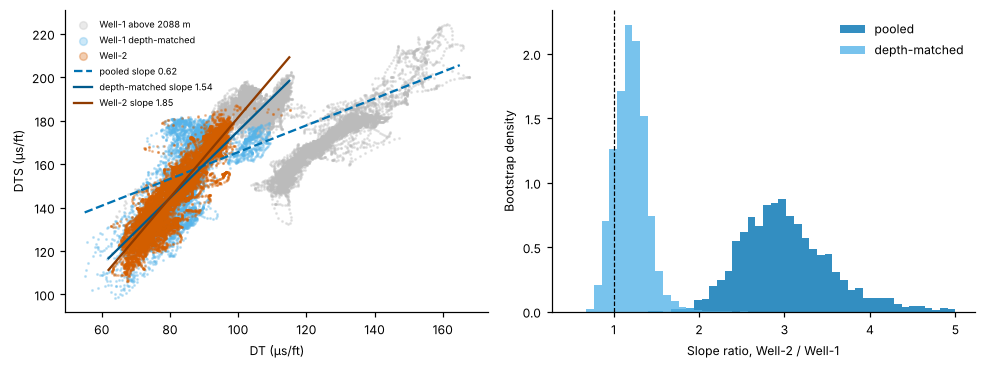

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
sh = w1[w1.MD < DEEP_TOP]
ax[0].scatter(sh.DT, sh.DTS, s=1, c="#BBBBBB", alpha=.3, rasterized=True, label="Well-1 above %.0f m" % DEEP_TOP)
ax[0].scatter(w1d.DT, w1d.DTS, s=1, c="#56B4E9", alpha=.3, rasterized=True, label="Well-1 depth-matched")
ax[0].scatter(w2.DT, w2.DTS, s=1, c="#D55E00", alpha=.3, rasterized=True, label="Well-2")
xx = np.array([55, 165]); ax[0].plot(xx, i_g + s_g * xx, "--", c="#0072B2", label="pooled slope %.2f" % s_g)
xd = np.array([62, 115]); ax[0].plot(xd, i_d + s_d * xd, c="#005a8c", label="depth-matched slope %.2f" % s_d); ax[0].plot(xd, ib + sb * xd, c="#8f3b00", label="Well-2 slope %.2f" % sb)
ax[0].set(xlabel="DT (µs/ft)", ylabel="DTS (µs/ft)"); ax[0].legend(frameon=False, fontsize=6, markerscale=5, loc="upper left")
for dA, c, lab in [(w1, "#0072B2", "pooled"), (w1d, "#56B4E9", "depth-matched")]:
    ax[1].hist(boot_slope_ratio(dA, w2, BLOCK_M), bins=50, range=(0.5, 5), density=True, color=c, alpha=.8, label=lab)
ax[1].axvline(1, c="k", ls="--", lw=.8); ax[1].set(xlabel="Slope ratio, Well-2 / Well-1", ylabel="Bootstrap density"); ax[1].legend(frameon=False)
plt.tight_layout(); plt.show()

## 3.2 Predictive models and 4.2 internal and external validation (Tables 5 and 6)

The models are trained on Well-1 with a random 80/20 split. Well-2 is never used for fitting.

In [9]:
tr, te = train_test_split(w1, test_size=0.2, random_state=SEED)
Xtr, ytr, Xte, yte = tr[FEATS].values, tr.DTS.values, te[FEATS].values, te.DTS.values

rf = RandomForestRegressor(n_estimators=100, random_state=SEED, n_jobs=-1).fit(Xtr, ytr)
xg = xgb.XGBRegressor(objective="reg:squarederror", n_estimators=100, max_depth=5, learning_rate=0.1, reg_lambda=1.0,
                      random_state=SEED, n_jobs=-1).fit(Xtr, ytr)

class ScaledANN:
    def __init__(s, model, sx, sy): s.model, s.sx, s.sy = model, sx, sy
    def predict(s, X): return s.model.predict(s.sx.transform(X), verbose=0).ravel() * s.sy.scale_[0] + s.sy.mean_[0]

def build_ann(dim):
    m = tf.keras.Sequential([tf.keras.layers.Input(shape=(dim,)),
        tf.keras.layers.Dense(64, activation="relu"), tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(32, activation="relu"), tf.keras.layers.Dropout(0.2),
        tf.keras.layers.Dense(16, activation="relu"), tf.keras.layers.Dense(1)])
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse"); return m

fit_df, val_df = (tr, te) if ANN_VALIDATION == "test" else train_test_split(tr, test_size=0.1, random_state=SEED)
sx = StandardScaler().fit(fit_df[FEATS].values); sy = StandardScaler().fit(fit_df[["DTS"]].values)
ann_net = build_ann(len(FEATS))
ann_net.fit(sx.transform(fit_df[FEATS].values), sy.transform(fit_df[["DTS"]].values).ravel(),
            validation_data=(sx.transform(val_df[FEATS].values), sy.transform(val_df[["DTS"]].values).ravel()),
            epochs=ANN_EPOCHS, batch_size=32, verbose=0,
            callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)])
ann = ScaledANN(ann_net, sx, sy)

MODELS = {"RF": rf, "XGB": xg, "ANN": ann}
y2 = w2.DTS.values
for m, mod in MODELS.items():
    w2["DTS_" + m] = mod.predict(w2[FEATS].values); w2["e_" + m] = w2["DTS_" + m] - y2

rows = []
for m, mod in MODELS.items():
    pi, pe = mod.predict(Xte), w2["DTS_" + m].values
    ri, re = r2_score(yte, pi), r2_score(y2, pe)
    rows.append({"model": m, "R2 internal": ri, "RMSE internal": mean_squared_error(yte, pi) ** .5, "MAE internal": mean_absolute_error(yte, pi),
                 "R2 external": re, "RMSE external": mean_squared_error(y2, pe) ** .5, "MAE external": mean_absolute_error(y2, pe),
                 "bias external": (pe - y2).mean(), "drop (R2 points)": ri - re, "drop (%)": 100 * (ri - re) / ri})
display(pd.DataFrame(rows).set_index("model"))

,R2 internal,RMSE internal,MAE internal,R2 external,RMSE external,MAE external,bias external,drop (R2 points),drop (%)
model,,,,,,,,,
RF,0.956,3.977,2.528,0.790,7.392,5.744,-2.368,0.166,17.370
XGB,0.934,4.903,3.487,0.817,6.897,5.322,-3.135,0.116,12.451
ANN,0.915,5.557,3.951,0.810,7.028,5.375,0.140,0.104,11.411


In [10]:
# Mincer-Zarnowitz decomposition of the Well-2 mean squared error
rows = []
for m in MODELS:
    yh = w2["DTS_" + m].values; e = y2 - yh; c, a = ols(yh, y2); bias = e.mean(); mse = (e ** 2).mean()
    rows.append({"model": m, "MZ intercept": a, "MZ slope": c, "bias (%MSE)": 100 * bias ** 2 / mse,
                 "slope (%MSE)": 100 * (((a + c * yh - yh) ** 2).mean() - bias ** 2) / mse,
                 "scatter (%MSE)": 100 * ((y2 - (a + c * yh)) ** 2).mean() / mse,
                 "R2 raw": r2_score(y2, yh), "R2 bias-only": r2_score(y2, yh + bias), "R2 linear": r2_score(y2, a + c * yh)})
display(pd.DataFrame(rows).set_index("model"))

,MZ intercept,MZ slope,bias (%MSE),slope (%MSE),scatter (%MSE),R2 raw,R2 bias-only,R2 linear
model,,,,,,,,
RF,15.280,0.910,10.265,3.864,85.871,0.790,0.812,0.820
XGB,6.126,0.979,20.657,0.217,79.126,0.817,0.855,0.855
ANN,-5.203,1.035,0.040,0.485,99.475,0.810,0.810,0.811


## 3.3 The interpretation term I and SHAP (Figures 5 and 6)

SHAP values are computed on depth-spaced rows of the Well-1 test split and of Well-2. I is the smallest Spearman correlation between the Well-1 and Well-2 mean |SHAP| feature ranks across the three algorithms. The interval uses a moving depth-block bootstrap of the explained rows.

In [11]:
def spaced(d, n): return d.iloc[np.unique(np.linspace(0, len(d) - 1, min(n, len(d))).round().astype(int))]

s1, s2 = spaced(te.sort_values("MD"), N_SHAP), spaced(w2, N_SHAP)
bg = tr[FEATS].sample(150, random_state=SEED).values

def shap_abs(m, X):
    if m == "ANN":
        v = np.array(shap.GradientExplainer(ann.model, ann.sx.transform(bg)).shap_values(ann.sx.transform(X)))
        return np.abs(v.squeeze(-1) if v.ndim == 3 else v) * ann.sy.scale_[0]
    return np.abs(shap.TreeExplainer(MODELS[m]).shap_values(X, check_additivity=False))

A = {m: (shap_abs(m, s1[FEATS].values), shap_abs(m, s2[FEATS].values)) for m in MODELS}
imp = pd.concat({m: pd.DataFrame({"Well-1": A[m][0].mean(0), "Well-2": A[m][1].mean(0)}, index=FEATS) for m in MODELS}, axis=1)
display(imp)

rho = {m: stats.spearmanr(A[m][0].mean(0), A[m][1].mean(0))[0] for m in MODELS}
I_obs = min(rho.values())

def block_rows(md, L):
    st = rng.uniform(md.min(), max(md.min(), md.max() - L), int(np.ceil((md.max() - md.min()) / L)))
    return np.concatenate([np.arange(np.searchsorted(md, s), np.searchsorted(md, s + L)) for s in st])

I_boot = np.array([min(stats.spearmanr(A[m][0][i1].mean(0), A[m][1][i2].mean(0))[0] for m in MODELS)
                   for i1, i2 in ((block_rows(s1.MD.values, BLOCK_M), block_rows(s2.MD.values, BLOCK_M)) for _ in range(N_BOOT))])
print("Spearman by algorithm:", {m: round(v, 3) for m, v in rho.items()})
print("I = %.2f, bootstrap median %.2f, 95%% interval %.2f to %.2f" % ((I_obs, np.median(I_boot)) + tuple(np.percentile(I_boot, [2.5, 97.5]))))

RF           XGB           ANN       
         Well-1 Well-2 Well-1 Well-2 Well-1 Well-2
DT       11.002 20.819 10.131 18.424 14.060 22.397
NPHI      4.305  6.685  5.371  9.420  5.424  4.868
RHOB      0.416  0.702  0.299  0.616  1.734  2.399
GR        0.707  0.717  0.651  0.667  1.534  1.343
RES_DEEP  3.947  1.064  4.024  1.049  6.985  4.226

Spearman by algorithm: {'RF': np.float64(1.0), 'XGB': np.float64(1.0), 'ANN': np.float64(0.9)}
I = 0.90, bootstrap median 0.90, 95% interval 0.80 to 0.90


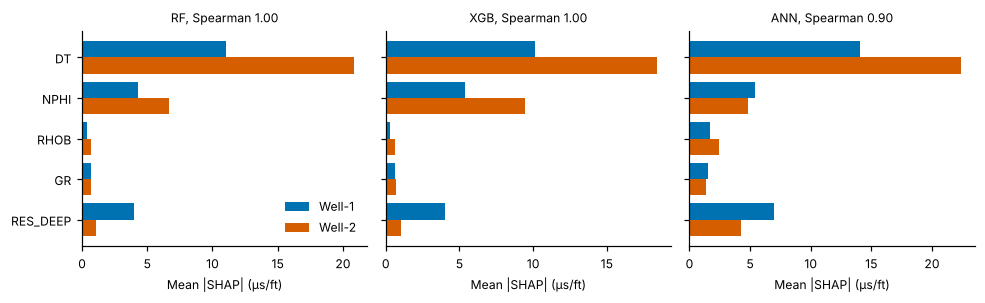

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(9, 2.8), sharey=True)
for a, m in zip(ax, MODELS):
    y = np.arange(len(FEATS)); a.barh(y - .2, A[m][0].mean(0), .4, label="Well-1", color="#0072B2"); a.barh(y + .2, A[m][1].mean(0), .4, label="Well-2", color="#D55E00")
    a.set_yticks(y); a.set_yticklabels(FEATS); a.invert_yaxis(); a.set_title("%s, Spearman %.2f" % (m, rho[m]), fontsize=8); a.set_xlabel("Mean |SHAP| (µs/ft)")
ax[0].legend(frameon=False); plt.tight_layout(); plt.show()

## 3.3 and 4.4 The Geological Transferability Index (Table 8, Figure 8)

GTI = (D · R · I)^(1/3). D is the share of Well-2 inside the 95 % Mahalanobis envelope of the Well-1 logs. R is the ratio of the smaller to the larger DT-DTS slope. I is fixed at its observed value in the bootstrap, which resamples depth blocks of both wells.

In [13]:
def gti_bootstrap(ref, I, L=BLOCK_M, B=N_BOOT):
    ins = in_env(ref, w2); BA, BB = Binned(ref), Binned(w2, flag=ins)
    out = []
    for _ in range(B):
        TA, TB = BA.boot(L, rng), BB.boot(L, rng)
        Db, Rb = TB[5] / TB[0], slope_ratio(Binned.slope(TA), Binned.slope(TB))
        out.append((Db, Rb, *gti_forms(Db, Rb, I).values()))
    return ins.mean(), slope_ratio(ols(ref.DT.values, ref.DTS.values)[0], sb), np.array(out)

rows = []; scen = {}
for lab, ref in [("pooled", w1), ("depth-matched", w1d)]:
    D, R, bo = gti_bootstrap(ref, I_obs); f = gti_forms(D, R, I_obs); scen[lab] = (D, R)
    ci = lambda j: "%.2f to %.2f" % tuple(np.percentile(bo[:, j], [2.5, 97.5]))
    rows.append({"Well-1 set": lab, "D": D, "D 95% CI": ci(0), "R": R, "R 95% CI": ci(1), "I": I_obs, "GTI": f["geometric"], "GTI 95% CI": ci(2),
                 "weakest link": f["weakest_link"], "arithmetic mean": f["arithmetic"],
                 "P(GTI > 0.8)": (bo[:, 2] > CLASS_HI).mean(), "P(GTI < 0.5)": (bo[:, 2] < CLASS_LO).mean()})
display(pd.DataFrame(rows).set_index("Well-1 set"))

# class share over all weight triples (step 0.01) for the weighted arithmetic index
n = 100; W = np.array([(i, j, n - i - j) for i in range(n + 1) for j in range(n + 1 - i)]) / n
share = {lab: (lambda g: {"Poor": (g < CLASS_LO).mean(), "Moderate": ((g >= CLASS_LO) & (g <= CLASS_HI)).mean(), "Transferable": (g > CLASS_HI).mean()})
         (W @ np.array([D, R, I_obs])) for lab, (D, R) in scen.items()}
display(pd.DataFrame(share).T)

,D,D 95% CI,R,R 95% CI,I,GTI,GTI 95% CI,weakest link,arithmetic mean,P(GTI > 0.8),P(GTI < 0.5)
Well-1 set,,,,,,,,,,,
pooled,0.781,0.67 to 0.86,0.334,0.21 to 0.47,0.900,0.617,0.52 to 0.70,0.334,0.672,0.000,0.009
depth-matched,0.850,0.75 to 0.94,0.834,0.61 to 0.99,0.900,0.861,0.77 to 0.92,0.834,0.862,0.886,0.000


,Poor,Moderate,Transferable
pooled,0.112,0.734,0.154
depth-matched,0.000,0.000,1.000


In [14]:
# sensitivity of the GTI interval to the block length
rows = []
for lab, ref in [("pooled", w1), ("depth-matched", w1d)]:
    for L in [50, 100, 200, 300, 500]:
        D, R, bo = gti_bootstrap(ref, I_obs, L=L); lo, hi = np.percentile(bo[:, 2], [2.5, 97.5])
        rows.append({"Well-1 set": lab, "block (m)": L, "GTI": (D * R * I_obs) ** (1 / 3), "2.5%": lo, "97.5%": hi, "width": hi - lo})
display(pd.DataFrame(rows))

,Well-1 set,block (m),GTI,2.5%,97.5%,width
0,pooled,50,0.617,0.550,0.675,0.125
1,pooled,100,0.617,0.524,0.703,0.179
2,pooled,200,0.617,0.466,0.753,0.287
3,pooled,300,0.617,0.401,0.830,0.428
4,pooled,500,0.617,0.000,0.879,0.879
5,depth-matched,50,0.861,0.786,0.922,0.136
6,depth-matched,100,0.861,0.757,0.928,0.171
7,depth-matched,200,0.861,0.730,0.929,0.198
8,depth-matched,300,0.861,0.724,0.935,0.211
9,depth-matched,500,0.861,0.742,0.940,0.198


## 4.5 The GTI and the accuracy loss across reference depth ranges (Table 9, Figure 9)

Each reference set is used to refit the three algorithms with the surrogate settings below. The accuracy drop is the internal random-split R² minus the external R² on Well-2. Ten disjoint equal-count depth bins provide a test that does not use nested sets.

In [15]:
def surrogate_row(ref):
    t_, e_ = train_test_split(ref, test_size=0.2, random_state=SEED); X, y = t_[FEATS].values, t_.DTS.values
    n_est = 50 if FAST else 200
    rf_ = RandomForestRegressor(n_estimators=n_est, max_depth=20, min_samples_split=5, min_samples_leaf=2, n_jobs=-1, random_state=SEED).fit(X, y)
    xg_ = xgb.XGBRegressor(n_estimators=n_est, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.7, random_state=SEED, n_jobs=-1).fit(X, y)
    sc = StandardScaler().fit(X)
    nets = [MLPRegressor(hidden_layer_sizes=(64, 32), early_stopping=True, n_iter_no_change=15, max_iter=300, random_state=s).fit(sc.transform(X), y) for s in range(N_MLP)]
    f = {"RF": rf_.predict, "XGB": xg_.predict, "ANN": lambda Z: np.mean([n_.predict(sc.transform(Z)) for n_ in nets], 0)}
    r = {"n": len(ref), "D": in_env(ref, w2).mean(), "R": slope_ratio(ols(ref.DT.values, ref.DTS.values)[0], sb)}
    r["GTI"] = (r["D"] * r["R"] * I_obs) ** (1 / 3)
    for m, p in f.items():
        r["int_" + m], r["ext_" + m] = r2_score(e_.DTS, p(e_[FEATS].values)), r2_score(y2, p(w2[FEATS].values))
    r["drop"] = np.mean([r["int_" + m] - r["ext_" + m] for m in f]); r["ext_mean"] = np.mean([r["ext_" + m] for m in f])
    return r

Z = [190, 2088, 2700] if FAST else [190, 1000, 1500, 1800, 2000, 2088, 2300, 2500, 2700]
nested = pd.DataFrame([{"top (m)": z, **surrogate_row(w1[w1.MD >= z].reset_index(drop=True))} for z in Z])
display(nested[["top (m)", "n", "D", "R", "GTI", "drop", "ext_mean"]])
print({c: round(stats.spearmanr(nested[c], nested["drop"])[0], 2) for c in ["GTI", "D", "R"]}, "Spearman with the accuracy drop, nested sets")

,top (m),n,D,R,GTI,drop,ext_mean
0,190,27033,0.781,0.334,0.617,0.145,0.789
1,1000,20341,0.827,0.641,0.781,0.160,0.781
2,1500,16261,0.809,0.938,0.881,0.161,0.772
3,1800,13308,0.831,1.000,0.908,0.122,0.788
4,2000,11308,0.851,0.891,0.880,0.140,0.747
5,2088,10428,0.850,0.835,0.861,0.133,0.744
6,2300,8676,0.825,0.817,0.847,0.240,0.654
7,2500,6965,0.779,0.749,0.807,0.256,0.601
8,2700,4979,0.758,0.613,0.748,0.311,0.470


{'GTI': np.float64(-0.52), 'D': np.float64(-0.82), 'R': np.float64(-0.52)} Spearman with the accuracy drop, nested sets


In [16]:
NB = 3 if FAST else 10
edges = np.quantile(w1.MD, np.linspace(0, 1, NB + 1)); edges[-1] += 1
bins = pd.DataFrame([{"bin": i + 1, **surrogate_row(w1[(w1.MD >= edges[i]) & (w1.MD < edges[i + 1])].reset_index(drop=True))} for i in range(NB)])
display(bins[["bin", "n", "D", "R", "GTI", "drop", "ext_mean"]])
for c in ["D", "R", "GTI"]:
    r_, p_ = stats.spearmanr(bins[c], bins["drop"]); print("%s vs drop, disjoint bins: rho = %.2f, p = %.3f" % (c, r_, p_))

,bin,n,D,R,GTI,drop,ext_mean
0,1,2704,0.000,0.582,0.000,20.265,-19.393
1,2,2703,0.000,0.513,0.000,36.008,-35.154
2,3,2703,0.000,0.369,0.000,21.454,-20.554
3,4,2703,0.001,0.497,0.079,4.499,-3.790
4,5,2703,0.001,0.091,0.041,1.843,-1.158
5,6,2704,0.031,0.863,0.290,1.574,-0.933
6,7,2703,0.391,0.145,0.371,1.934,-1.336
7,8,2703,0.086,0.978,0.422,2.670,-1.867
8,9,2703,0.634,0.588,0.695,0.262,0.560
9,10,2704,0.654,0.564,0.693,0.454,0.236


D vs drop, disjoint bins: rho = -0.84, p = 0.002
R vs drop, disjoint bins: rho = -0.25, p = 0.489
GTI vs drop, disjoint bins: rho = -0.84, p = 0.002


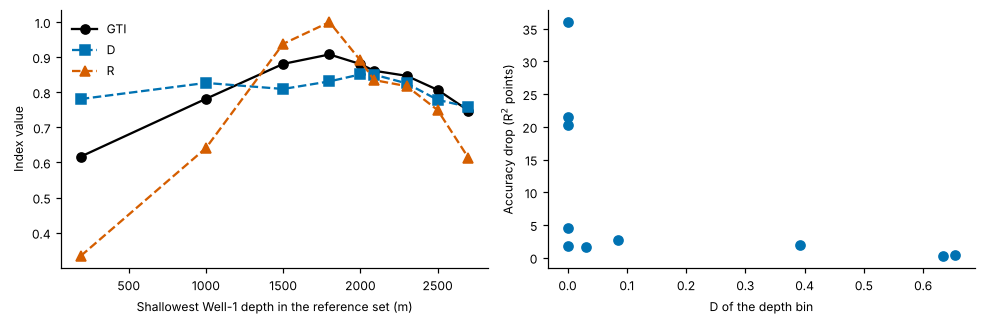

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].plot(nested["top (m)"], nested.GTI, "ko-", label="GTI"); ax[0].plot(nested["top (m)"], nested.D, "s--", c="#0072B2", label="D"); ax[0].plot(nested["top (m)"], nested.R, "^--", c="#D55E00", label="R")
ax[0].set(xlabel="Shallowest Well-1 depth in the reference set (m)", ylabel="Index value"); ax[0].legend(frameon=False)
ax[1].scatter(bins.D, bins["drop"], c="#0072B2"); ax[1].set(xlabel="D of the depth bin", ylabel="Accuracy drop (R$^2$ points)")
plt.tight_layout(); plt.show()

## 4.6 Algorithm spread as uncertainty (Table 10)

The spread among RF, XGB and ANN on Well-2 is compared with the error against the measured DTS. Intervals for R² and coverage use a 100 m block bootstrap of Well-2.

In [18]:
P = np.stack([w2["DTS_" + m].values for m in MODELS], 1)
mu_e, sd_e, err = P.mean(1), P.std(1, ddof=1), P.mean(1) - y2
lo, hi = P.min(1), P.max(1)
E = np.corrcoef((P - y2[:, None]).T)

def r2(y, p): return 1 - ((y - p) ** 2).sum() / ((y - y.mean()) ** 2).sum()
g = block_id(w2, 100); idx = [np.where(g == u)[0] for u in np.unique(g)]
bs = []
for _ in range(N_BOOT):
    ii = np.concatenate([idx[j] for j in rng.integers(0, len(idx), len(idx))]); yy = y2[ii]
    bs.append([r2(yy, P[ii, j]) for j in range(3)] + [((yy >= lo[ii]) & (yy <= hi[ii])).mean()])
bs = np.array(bs)
q = lambda j: "%.3f (%.3f to %.3f)" % (np.median(bs[:, j]), *np.percentile(bs[:, j], [2.5, 97.5]))
t10 = pd.Series({**{"R2 external " + m: q(j) for j, m in enumerate(MODELS)},
    "coverage of the min-max envelope": q(3),
    "coverage of mean +/- 2 SD": "%.3f" % (np.abs(err) <= 2 * sd_e).mean(),
    "mean pointwise SD (µs/ft)": "%.2f" % sd_e.mean(), "ensemble RMSE (µs/ft)": "%.2f" % np.sqrt((err ** 2).mean()),
    "Spearman |error| vs SD": "%.2f" % stats.spearmanr(np.abs(err), sd_e)[0],
    "error correlation RF-XGB / RF-ANN / XGB-ANN": "%.2f / %.2f / %.2f" % (E[0, 1], E[0, 2], E[1, 2])})
display(t10.to_frame("value"))

,value
R2 external RF,0.776 (0.616 to 0.849)
R2 external XGB,0.805 (0.671 to 0.870)
R2 external ANN,0.798 (0.687 to 0.850)
coverage of the min-max envelope,0.358 (0.302 to 0.426)
coverage of mean +/- 2 SD,0.595
mean pointwise SD (µs/ft),3.01
ensemble RMSE (µs/ft),6.47
Spearman |error| vs SD,-0.09
error correlation RF-XGB / RF-ANN / XGB-ANN,0.87 / 0.71 / 0.78


## 4.7 Calibration design and residual-correction transfer learning (Table 11, Figures 10 and 11)

Calibration rows come from Well-2 and the evaluation rows are the remaining Well-2 rows. The Well-1 scalers are reused.

In [19]:
def calibration_split(frac, placement):
    n = len(w2); k = max(1, int(round(frac * n)))
    idx = {"top": np.arange(k), "bottom": np.arange(n - k, n), "middle": np.arange((n - k) // 2, (n - k) // 2 + k),
           "random": np.random.default_rng(SEED).choice(n, k, replace=False)}[placement]
    m = np.zeros(n, bool); m[idx] = True
    return w2[m], w2[~m]

def adapt(m, cal):
    Xc, yc = cal[FEATS].values, cal.DTS.values
    if m == "XGB":
        return xgb.XGBRegressor(n_estimators=30, max_depth=5, learning_rate=0.1, random_state=SEED).fit(Xc, yc, xgb_model=xg.get_booster()).predict
    if m == "RF":
        r_ = copy.deepcopy(rf); r_.warm_start = True; r_.n_estimators = rf.n_estimators + 30
        return r_.fit(Xc, yc).predict
    net = tf.keras.models.clone_model(ann.model); net.set_weights(ann.model.get_weights())
    net.compile(optimizer=tf.keras.optimizers.Adam(1e-4), loss="mse")
    net.fit(ann.sx.transform(Xc), ann.sy.transform(yc.reshape(-1, 1)).ravel(), epochs=25, batch_size=min(32, len(Xc)), verbose=0)
    return ScaledANN(net, ann.sx, ann.sy).predict

rows = []
for frac in [0.05, 0.10, 0.20]:
    for place in ["top", "middle", "bottom", "random"]:
        cal, ev = calibration_split(frac, place)
        for m in MODELS:
            rows.append({"fraction": frac, "placement": place, "model": m,
                         "R2 zero-shot": r2_score(ev.DTS, MODELS[m].predict(ev[FEATS].values)),
                         "R2 adapted": r2_score(ev.DTS, adapt(m, cal)(ev[FEATS].values))})
tl = pd.DataFrame(rows)
display(tl[tl.fraction == 0.20].pivot(index="placement", columns="model", values=["R2 zero-shot", "R2 adapted"]))

R2 zero-shot             R2 adapted             
model              ANN    RF   XGB        ANN    RF    XGB
placement                                                 
bottom           0.790 0.744 0.770      0.813 0.764  0.809
middle           0.818 0.812 0.842      0.761 0.833  0.773
random           0.810 0.790 0.818      0.874 0.851  0.915
top              0.710 0.654 0.701     -2.339 0.557 -2.961

In [20]:
# bias-only and linear recalibration of the zero-shot predictions
def recal_r2(idx, yh, mode):
    mask = np.zeros(len(y2), bool); mask[idx] = True
    if mode == "bias": pr = yh + (y2[mask] - yh[mask]).mean()
    else: c, a = ols(yh[mask], y2[mask]); pr = a + c * yh
    return r2_score(y2[~mask], pr[~mask])

N = len(y2); REP = 5 if FAST else 30; rows = []
for m in ["XGB", "RF"]:
    yh = w2["DTS_" + m].values
    for frac in [0.005, 0.01, 0.02, 0.05, 0.10, 0.20]:
        n_ = max(int(frac * N), 5)
        for mode in ["bias", "linear"]:
            rnd = [recal_r2(rng.choice(N, n_, replace=False), yh, mode) for _ in range(REP)]
            rows.append({"model": m, "fraction": frac, "mode": mode, "random median": np.median(rnd),
                         "top": recal_r2(np.arange(n_), yh, mode), "middle": recal_r2(np.arange((N - n_) // 2, (N - n_) // 2 + n_), yh, mode),
                         "bottom": recal_r2(np.arange(N - n_, N), yh, mode)})
display(pd.DataFrame(rows))

,model,fraction,mode,random median,top,middle,bottom
0,XGB,0.005,bias,0.855,0.852,0.795,0.506
1,XGB,0.005,linear,0.852,0.481,0.330,-2.600
2,XGB,0.010,bias,0.855,0.838,0.816,0.513
3,XGB,0.010,linear,0.854,-0.262,-0.059,-4.413
4,XGB,0.020,bias,0.855,0.844,0.817,0.581
5,XGB,0.020,linear,0.855,-0.112,0.510,-2.520
6,XGB,0.050,bias,0.855,0.833,0.800,0.693
7,XGB,0.050,linear,0.855,-0.657,0.784,0.632
8,XGB,0.100,bias,0.855,0.812,0.827,0.738
9,XGB,0.100,linear,0.855,-2.749,0.823,0.687


## 4.8 Consequences for shear modulus and Poisson's ratio (Table 12)

G = ρ·Vs² and ν from Vp and Vs, with Vp = 304800/DT and Vs = 304800/DTS in m/s. The weak-rock threshold is the lowest quartile of the measured G. The bias fix uses the median of 30 random 1 % calibration samples.

In [21]:
def geo(DT, DTS, RHOB):
    Vp, Vs = 304800 / DT, 304800 / DTS
    return RHOB * 1000 * Vs ** 2 / 1e9, (Vp ** 2 - 2 * Vs ** 2) / (2 * (Vp ** 2 - Vs ** 2))

G0, nu0 = geo(w2.DT.values, y2, w2.RHOB.values); G_thr = np.percentile(G0, 25); weak = G0 < G_thr
rows = []
for m in MODELS:
    yh = w2["DTS_" + m].values
    off = np.median([(y2[i] - yh[i]).mean() for i in (rng.choice(N, int(0.01 * N), replace=False) for _ in range(30))])
    for state, dts in [("zero-shot", yh), ("bias fix, 1% sample", yh + off)]:
        G, nu = geo(w2.DT.values, dts, w2.RHOB.values); e = 100 * (G - G0) / G0
        rows.append({"model": m, "state": state, "median G error (%)": np.median(e), "G MAE (GPa)": np.abs(G - G0).mean(),
                     "rows with G error > 10% (%)": 100 * (e > 10).mean(), "rows with G error > 20% (%)": 100 * (e > 20).mean(),
                     "weak rock called safe (%)": 100 * ((G >= G_thr) & weak).sum() / weak.sum(), "nu MAE": np.abs(nu - nu0).mean()})
display(pd.DataFrame(rows))

,model,state,median G error (%),G MAE (GPa),rows with G error > 10% (%),rows with G error > 20% (%),weak rock called safe (%),nu MAE
0,RF,zero-shot,4.247,0.891,23.464,3.979,15.516,0.027
1,RF,"bias fix, 1% sample",0.903,0.792,12.026,2.103,10.832,0.023
2,XGB,zero-shot,4.661,0.840,23.930,3.857,16.004,0.025
3,XGB,"bias fix, 1% sample",0.155,0.710,9.029,1.609,9.878,0.021
4,ANN,zero-shot,-0.128,0.827,12.032,2.331,19.778,0.025
5,ANN,"bias fix, 1% sample",0.155,0.826,12.642,2.453,20.155,0.025
